In [ ]:
import pandas as pd
import numpy as np

# 1. SIMULACIÓN DE TU DATAFRAME 2D (Resultado de tu ETL MINSA + SENAMHI + ENFEN)
# Imaginemos 10 semanas históricas para un distrito específico (ej. Piura)
datos = {
    'Semana': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'Temp_Max_Senamhi': [31.5, 32.0, 34.1, 33.5, 35.0, 34.8, 32.1, 31.0, 30.5, 30.0],
    'Precipitacion_Senamhi': [0, 15, 45, 10, 80, 20, 5, 0, 0, 0],
    'TSM_Enfen': [24.1, 24.5, 25.0, 25.2, 26.1, 25.8, 24.9, 24.5, 24.0, 23.8],
    'Casos_Dengue_Minsa': [2, 5, 8, 12, 45, 110, 150, 80, 40, 15]
}
df_etl = pd.DataFrame(datos)
print()

In [ ]:
print(len(df_etl))
print(df_etl.shape)

10
(10, 5)


In [ ]:


# 2. EL MOTOR DE TRANSFORMACIÓN (Ventana Deslizante)
def transformar_a_tensor_3d(df, columnas_features, columna_target, semanas_historial):
    X, y = [], []

    # Extraemos solo los valores numéricos como matrices de NumPy
    valores_features = df[columnas_features].values
    valores_target = df[columna_target].values

    # Iteramos limitando el final para no buscar datos que no existen
    for i in range(len(df) - semanas_historial):

        # X: Cortamos un "bloque" de tiempo (ej. de la semana 1 a la 3)
        bloque_x = valores_features[i : i + semanas_historial]

        # Y: Tomamos el valor objetivo de la semana SIGUIENTE al bloque (ej. semana 4)
        valor_y = valores_target[i + semanas_historial]

        X.append(bloque_x)
        y.append(valor_y)

    # Convertimos las listas resultantes a Tensores de NumPy
    return np.array(X), np.array(y)



In [ ]:
# 3. EJECUCIÓN DE LA TRANSFORMACIÓN
# Definimos los parámetros del modelo
FEATURES = ['Temp_Max_Senamhi', 'Precipitacion_Senamhi', 'TSM_Enfen']
TARGET = 'Casos_Dengue_Minsa'
VENTANA_TIEMPO = 3 # La CNN mirará 3 semanas hacia el pasado

X_tensor, y_tensor = transformar_a_tensor_3d(df_etl, FEATURES, TARGET, VENTANA_TIEMPO)

# 4. VERIFICACIÓN DE LA ARQUITECTURA (El paso más crítico antes de Keras)
print("--- ANÁLISIS DE DIMENSIONES ---")
print(f"Dataframe Original 2D : {df_etl[FEATURES].shape} -> (Filas totales, Columnas)")
print(f"Tensor X 3D para CNN  : {X_tensor.shape} -> (Muestras, Pasos_de_Tiempo, Características)")
print(f"Vector Y de Etiquetas : {y_tensor.shape}  -> (Muestras,)")

print("\n--- LO QUE VE LA RED NEURONAL EN LA MUESTRA 0 ---")
print("Entrada X (Clima de las Semanas 1, 2 y 3):")
print(X_tensor[0])
print(f"Salida Esperada Y (Casos en la Semana 4): {y_tensor[0]}")

--- ANÁLISIS DE DIMENSIONES ---
Dataframe Original 2D : (10, 3) -> (Filas totales, Columnas)
Tensor X 3D para CNN  : (7, 3, 3) -> (Muestras, Pasos_de_Tiempo, Características)
Vector Y de Etiquetas : (7,)  -> (Muestras,)

--- LO QUE VE LA RED NEURONAL EN LA MUESTRA 0 ---
Entrada X (Clima de las Semanas 1, 2 y 3):
[[31.5  0.  24.1]
 [32.  15.  24.5]
 [34.1 45.  25. ]]
Salida Esperada Y (Casos en la Semana 4): 12


# ***Muestras***:
## Cada Matriz de distinto color

# ***Pasos_de_Tiempo***:
## Cada fila de cada matriz

# ***Características***:
## Cada columna de cada matriz

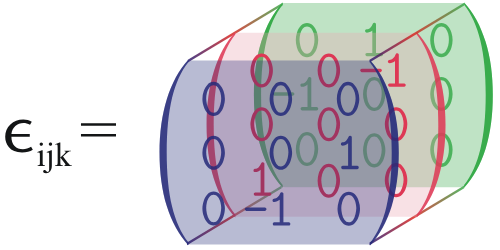

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
from tensorflow.keras.optimizers import Adam

# Recuperamos las dimensiones de tu tensor X generado en el paso anterior
# X_tensor.shape es (muestras, 3, 3) -> (muestras, pasos_de_tiempo, características)
PASOS_DE_TIEMPO = X_tensor.shape[1]
CARACTERISTICAS = X_tensor.shape[2]

# 1. Definición de la Arquitectura
modelo_dengue = Sequential([
    # CAPA DE EXTRACCIÓN DE CARACTERÍSTICAS TEMPORALES
    # filters=32: Crearemos 32 "linternas" distintas para buscar diferentes patrones climáticos.
    # kernel_size=2: La linterna lee bloques de 2 semanas contiguas en cada salto.
    Conv1D(filters=32, kernel_size=2, activation='relu',
           input_shape=(PASOS_DE_TIEMPO, CARACTERISTICAS)),

    # CAPA DE REDUCCIÓN (Submuestreo)
    # pool_size=2: De las señales extraídas, se queda solo con el pico más fuerte.
    MaxPooling1D(pool_size=2),

    # APLANAMIENTO
    # Rompe la estructura 3D y pone todos los hallazgos en una sola línea plana (1D)
    Flatten(),

    # CAPA OCULTA DE TOMA DE DECISIONES
    # Una red neuronal densa tradicional para interpretar los patrones encontrados
    Dense(64, activation='relu'),

    # CAPA DE SALIDA
    # OJO: Solo 1 neurona con activación lineal, porque queremos predecir un número continuo.
    Dense(1, activation='linear')
])

# 2. Compilación del Modelo
# loss='mse': Error Cuadrático Medio, ideal para penalizar predicciones muy alejadas de la realidad.
# metrics='mae': Error Absoluto Medio, te dirá "te equivocaste por X casos de dengue en promedio".
modelo_dengue.compile(optimizer=Adam(learning_rate=0.001),
                      loss='mse',
                      metrics=['mae'])

# 3. Resumen de la red
modelo_dengue.summary()

# 4. Entrenamiento (Asumiendo que ya separaste en Train y Test)
# historial = modelo_dengue.fit(X_tensor, y_tensor, epochs=50, batch_size=16, validation_split=0.2)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_15 (Conv1D)              │ (None, 2, 32)          │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_15 (MaxPooling1D) │ (None, 1, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_15 (Flatten)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,401 (9.38 KB)

 Trainable params: 2,401 (9.38 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import matplotlib.pyplot as plt

# 1. PARTICIÓN CRONOLÓGICA (Train / Test Split Temporal)
# Asumimos que X_tensor e y_tensor ya están ordenados por fecha de la semana 1 a la N
total_muestras = len(X_tensor)
indice_corte = int(total_muestras * 0.8) # 80% para entrenamiento, 20% para prueba

# Cortamos los tensores limpiamente sin alterar el orden del tiempo
X_train = X_tensor[:indice_corte]
y_train = y_tensor[:indice_corte]

X_test = X_tensor[indice_corte:]
y_test = y_tensor[indice_corte:]

print(f"Muestras de Entrenamiento: {len(X_train)} (Pasado)")
print(f"Muestras de Prueba: {len(X_test)} (Futuro a predecir)")

from tensorflow.keras.callbacks import EarlyStopping

# 1. Configuración del supervisor (EarlyStopping)
supervisor_entrenamiento = EarlyStopping(
    monitor='val_loss',          # Métrica a vigilar: el error en los datos inéditos (línea roja)
    patience=5,                  # Margen de tolerancia: espera 5 épocas para confirmar la tendencia
    restore_best_weights=True,   # ¡La clave!: Retrocede en el tiempo y guarda los pesos de la mejor época
    verbose=1                    # Imprime un mensaje cuando detiene el entrenamiento
)

print("Iniciando el entrenamiento supervisado...")

# 2. Entrenamiento con el Callback conectado
# Puedes configurar 100 épocas; el supervisor lo detendrá mucho antes si detecta sobreajuste.
historial = modelo_dengue.fit(
    X_train, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    callbacks=[supervisor_entrenamiento], # Conectamos el cable del supervisor al motor
    verbose=1
)

# # 3. GRAFICANDO LA CURVA DE APRENDIZAJE
# # Extraemos las métricas del historial
# perdida_train = historial.history['loss'] # Error Cuadrático Medio en entrenamiento
# perdida_val = historial.history['val_loss'] # Error Cuadrático Medio en validación

# mae_train = historial.history['mae'] # Error Absoluto Medio (en cantidad de casos)
# mae_val = historial.history['val_mae']

# epocas = range(1, len(perdida_train) + 1)

# # Creamos la figura con dos gráficos
# plt.figure(figsize=(14, 5))

# # Gráfico 1: Evolución de la Función de Pérdida (MSE)
# plt.subplot(1, 2, 1)
# plt.plot(epocas, perdida_train, 'b-', label='Pérdida en Entrenamiento (MSE)')
# plt.plot(epocas, perdida_val, 'r-', label='Pérdida en Validación (MSE)')
# plt.title('Disminución del Error Cuadrático Medio')
# plt.xlabel('Épocas')
# plt.ylabel('MSE')
# plt.legend()

# # Gráfico 2: Evolución del Error Absoluto Medio (MAE)
# # Esta métrica es más fácil de leer: te dice por cuántos pacientes se equivoca el modelo
# plt.subplot(1, 2, 2)
# plt.plot(epocas, mae_train, 'b-', label='MAE Entrenamiento')
# plt.plot(epocas, mae_val, 'r-', label='MAE Validación')
# plt.title('Margen de Error (Pacientes de Diferencia)')
# plt.xlabel('Épocas')
# plt.ylabel('Cantidad de Casos (MAE)')
# plt.legend()

# plt.tight_layout()
# plt.show()

# 4. EVALUACIÓN FINAL CON LOS DATOS DE PRUEBA (El futuro real)
print("\n--- EVALUACIÓN EN EL CONJUNTO DE PRUEBA (DATOS INÉDITOS) ---")
resultados = modelo_dengue.evaluate(X_test, y_test, verbose=0)
print(f"Error Absoluto Medio final (MAE): {resultados[1]:.2f} casos de dengue de margen de error.")

Muestras de Entrenamiento: 5 (Pasado)
Muestras de Prueba: 2 (Futuro a predecir)
Iniciando el entrenamiento supervisado...
Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - loss: 13214.0498 - mae: 98.8654 - val_loss: 9083.8389 - val_mae: 95.3092
Epoch 2/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - loss: 12752.5811 - mae: 96.7542 - val_loss: 8668.0400 - val_mae: 93.1023
Epoch 3/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - loss: 12310.9561 - mae: 94.6938 - val_loss: 8264.6094 - val_mae: 90.9099
Epoch 4/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - loss: 11887.5098 - mae: 92.6930 - val_loss: 7873.8975 - val_mae: 88.7350
Epoch 5/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - loss: 11477.6133 - mae: 90.7208 - val_loss: 7491.8633 - val_mae: 86.5555
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - loss: 11080.1689 - mae: 88.7749 - val_loss: 7091.3677 - val_mae: 84.2103
Epoch 7/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - loss: 10693.0215 - mae: 86.8495 - val_loss: 6702.2861 - val_mae: 81.8675
Epoch